# LightGBM Baseline for Fraud Detection
**ST1519 Agile MLOps CA1 | PBI 02 | Eaint Chu Nay Chi**

## 1. Model Objective
The aim is to identify potentially fraudulent SP-buy orders so that Trust & Safety analysts can review suspicious transactions. Useful alerts should catch fraud without creating too many unnecessary investigations of genuine customers.

I use **one LightGBM baseline configuration** and train it independently on two feature datasets:

| Run | Features | Purpose |
|---|---|---|
| `lightgbm_chu_safe` | Features retained by the team's Safe preparation rules | Candidate for team model selection |
| `lightgbm_chu_full` | Safe features plus uncertain customer snapshots | Exploratory comparison for potential leakage |

This is a **feature-set comparison**, not a baseline-versus-improved-model experiment. There is no hyperparameter search or early stopping. The discussion below refers to the displayed saved run; review it when data or settings change.

## 2. Why LightGBM
LightGBM is a gradient boosting algorithm. It builds trees one after another, with each new tree helping to reduce the errors of the existing ensemble. For this binary classification task, the combined prediction is expressed as a fraud score between 0 and 1.

**Why it is suitable here**

- **Nonlinear patterns:** it can learn combinations of order value, account age and payment-related features.
- **Efficient training:** histogram-based splits group feature values into bins, reducing split-search cost.
- **No scaling needed:** the shared data is already numeric, and tree splits do not require standardization.
- **Different learning approach:** unlike independently randomized Extra Trees, boosting fits trees sequentially to improve the ensemble.

LightGBM grows trees leaf-wise, expanding the leaf with the largest loss reduction. This can produce overly complex trees, so the baseline limits leaves and minimum examples per leaf. Fast training alone does not establish predictive quality; the held-out results below provide that evidence.

Algorithm reference: [LightGBM features and leaf-wise growth](https://lightgbm.readthedocs.io/en/stable/Features.html).

## 3. Imports and Configuration
Model construction and training live in `src/lightgbm_chu.py`. I reuse `model_utils.py`, `data_split.py` and `mlflow_utils.py` so the dataset checks, split boundaries, evaluation metrics and logging follow the team's conventions.

The notebook uses the project `.venv` kernel and local MLflow storage for development. The command-line script can read the team's tracking URI from an environment variable when shared logging is ready.

In [1]:
import os
import sys
import json
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "lightgbm_chu.py").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import numpy as np
import pandas as pd
import model_utils as mu
import lightgbm_chu as lgb
import lightgbm
import mlflow
import mlflow.sklearn
from mlflow_utils import log_trained_model
from data_processing import SNAPSHOT_FEATURES
from data_split import create_split_labels, TRAIN_END, VAL_END
from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
%matplotlib inline

DATA_DIR = Path(os.environ.get("FRAUD_DATA_DIR", ROOT / "data" / "processed"))
OUTPUT_DIR = ROOT / "outputs"
REPORT_DIR = OUTPUT_DIR / lgb.SHORT_NAME
REPORT_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT = "SP-buy-Fraud-Detection"
LOG_TO_MLFLOW = True
DEVELOPER = "chu"
workflow_started = time.perf_counter()
print("Repository:", ROOT)
print("Python:", sys.executable)
print("LightGBM:", lightgbm.__version__)
print("Random seed:", mu.RANDOM_SEED)

Repository: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5
Python: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5\.venv\Scripts\python.exe
LightGBM: 4.7.0
Random seed: 42


## 4. Load and Check the Datasets
Before training, I check the required columns, binary target values, duplicate country/order keys and missing or infinite feature values. I also verify that both files contain the same orders and labels in the same order.

The SHA-256 checksum records the exact file used. This helps distinguish changed input data from changed model code when reproducing results.

In [2]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)
df_safe = mu.load_feature_data(safe_path)
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)
checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
display(pd.DataFrame({
    "Rows": [len(df_safe), len(df_full)],
    "Features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "Fraud rate (%)": [100 * df_safe.is_fraud.mean(), 100 * df_full.is_fraud.mean()],
    "SHA256": [checksums["safe"], checksums["full"]],
}, index=["Safe", "Full"]))

,Rows,Features,Fraud rate (%),SHA256
Safe,949872,31,10.993271,656a05ca11891816989d51eeaf4c706aab2e9b38682fdf...
Full,949872,41,10.993271,d5abc1ac0ce107b1118a47327965b2ba1393f917a59b4f...


### Insight from Dataset Checks
Both datasets passed the shared validation checks. They contain **949,872 orders**, with an overall fraud rate of **10.99%**. Safe contains **31 model inputs**, while Full contains **41**.

Since the rows and labels match, differences in their results are not caused by evaluating different orders. Passing these checks confirms structural consistency; it does not establish that every feature was available at the original prediction time.

## 5. Feature Selection and Leakage Prevention
The raw identifiers, order date, raw country code and target are excluded from the model inputs. Country information remains through numeric one-hot columns. **`refund_value` is excluded** because it may reveal information recorded after the fraud assessment.

The Full dataset adds the team's customer snapshot features. Their historical timing is uncertain, so I keep them separate from the Safe production candidate rather than assuming they were available for each order.

In [3]:
safe_features = mu.get_feature_columns(df_safe)
full_features = mu.get_feature_columns(df_full)
extra_features = sorted(set(full_features) - set(safe_features))
assert set(safe_features).issubset(full_features)
assert set(extra_features) == set(SNAPSHOT_FEATURES)
assert "refund_value" not in safe_features + full_features
print("Safe features:", len(safe_features))
print("Full features:", len(full_features))
print("Excluded snapshot features:")
for feature in extra_features:
    print("-", feature)

Safe features: 31
Full features: 41
Excluded snapshot features:
- associated_capped
- avg_payment_per_order
- cancel_rate
- log_num_associated_customers
- log_num_cancelled_orders_last_50days
- log_num_orders_last_50days
- log_num_refund_orders_last_50days
- log_total_payment_last_50days
- mobile_verified
- refund_rate


### Insight from Feature Selection
The **10 additional Full features** match `SNAPSHOT_FEATURES` exactly. Therefore, this experiment changes the feature set while keeping the baseline configuration fixed.

The name **Safe** follows the team's preparation rules. It does not prove the timing of every remaining feature: for example, `account_age_days` still depends on a customer-derived first-order date whose provenance should be checked.

## 6. Shared Chronological Split

| Split | Period | Use in this notebook |
|---|---|---|
| Train | Up to 15 March 2023 | Fit the trees |
| Validation | 16 March to 13 April 2023 | Choose the Safe fraud threshold |
| Test | 14 April 2023 onwards | Report final held-out performance |

A chronological split better represents predicting later orders. A random split could mix later observations into training while earlier orders are being evaluated. Both datasets use identical split labels. Validation does not tune model settings or stop tree fitting in this baseline.

In [4]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full))
split_summary = (df_safe.assign(split=split).groupby("split").agg(
    first_date=("order_date", "min"), last_date=("order_date", "max"),
    orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
).loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = 100 * split_summary["orders"] / len(df_safe)
display(split_summary)

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.101511,70.101656
Validation,2023-03-16,2023-04-13,139874,18993,0.135786,14.725563
Test,2023-04-14,2023-05-11,144122,17835,0.123749,15.172781


### Insight from the Split
The data contains **665,876 training orders**, **139,874 validation orders** and **144,122 test orders**. Fraud prevalence changes from **10.15%** in Train to **13.58%** in Validation and **12.37%** in Test.

This shows a change in class distribution across periods. It is a reason to examine later-period performance carefully, but class prevalence alone cannot establish why a particular prediction error occurs.

## 7. Class Imbalance Analysis
Most orders are genuine. A classifier can obtain a high accuracy simply by predicting the majority class, while catching no fraud. I therefore report fraud **precision and recall**, supported by F1, average precision and ROC-AUC.

The fixed baseline uses inverse-frequency class weights. This gives fraud examples more weight during fitting; it does not create new fraud examples. Weighting can alter probability calibration, so model scores should not be read as verified real-world fraud probabilities.

,orders,percent
is_fraud,,
0,845450,89.01
1,104422,10.99


Train: 665,876 orders | fraud 10.15% | always-nonfraud accuracy 89.85%
Validation: 139,874 orders | fraud 13.58% | always-nonfraud accuracy 86.42%
Test: 144,122 orders | fraud 12.37% | always-nonfraud accuracy 87.63%


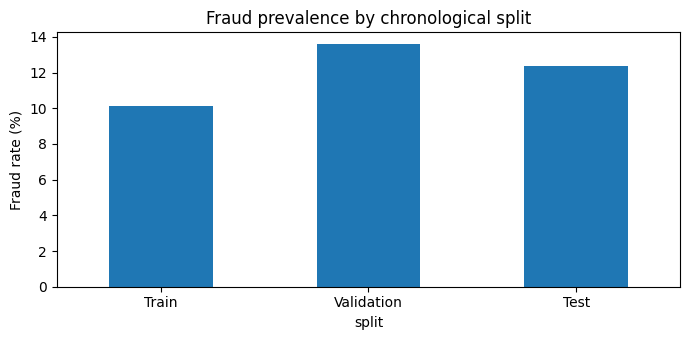

In [5]:
display(mu.class_balance(df_safe["is_fraud"]))
for name in ["Train", "Validation", "Test"]:
    y = df_safe.loc[split == name, "is_fraud"]
    print(f"{name}: {len(y):,} orders | fraud {y.mean():.2%} | "
          f"always-nonfraud accuracy {1-y.mean():.2%}")
ax = split_summary["fraud_rate"].mul(100).plot.bar(rot=0, figsize=(7, 3.5))
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud prevalence by chronological split")
plt.tight_layout()
plt.show()

### Insight from Class Imbalance
On the test period, predicting **Not Fraud for every order** would achieve **87.63% accuracy**, with **zero fraud recall**. This is why the model's usefulness must be assessed using fraud detection and false-alarm counts rather than accuracy alone.

Balanced weights are a baseline choice, not the result of a search. The threshold analysis below shows the practical trade-off produced by that choice.

## 8. Baseline Parameters
I keep one configuration for both datasets. The parameters below are chosen as a reproducible starting point, not claimed to be optimal.

| Parameter | Baseline | Reason |
|---|---|---|
| `objective` | binary | Fraud versus non-fraud |
| `n_estimators` | 100 | Fixed boosting rounds |
| `learning_rate` | 0.1 | Contribution of each boosting step |
| `num_leaves` | 31 | Limit leaf-wise tree complexity |
| `max_depth` | -1 | No depth cap; leaf count still limits complexity |
| `min_child_samples` | 20 | Minimum examples per leaf |
| `class_weight` | balanced | Inverse-frequency training weights |
| `random_state` | 42 | Fixed seed |
| `n_jobs` | -1 | Use available CPU threads |
| `deterministic`, `force_col_wise` | True | Consistent CPU training setup |

Parameter reference: [LightGBM classifier parameters and weighting caveats](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html). The documentation suggests `is_unbalance` or `scale_pos_weight` for binary weighting; this baseline retains its existing sklearn-style sample weighting rather than changing the experiment.

In [6]:
params = lgb.DEFAULT_PARAMS.copy()
display(pd.DataFrame(params.items(), columns=["Parameter", "Value"]))

,Parameter,Value
0,objective,binary
1,n_estimators,100
2,learning_rate,0.1
3,num_leaves,31
4,max_depth,-1
5,min_child_samples,20
6,class_weight,balanced
7,random_state,42
8,n_jobs,-1
9,verbosity,-1


## 9. Check Local MLflow and Model Saving
Before full training, I fit the same configuration on a small development subset and check whether the model can be saved and reloaded with matching predictions. This smoke test checks the workflow, not model quality.

The shared logger uses sklearn-compatible MLflow serialization with `skops`. Only the explicit LightGBM types produced by our own training are trusted. The notebook checks that the tracking store is local.

In [7]:
local_folder = (ROOT / "mlruns").resolve()
local_folder.mkdir(exist_ok=True)
local_uri = f"sqlite:///{(local_folder / 'mlflow.db').as_posix()}"
os.environ["MLFLOW_TRACKING_URI"] = local_uri
mlflow_location = mu.setup_mlflow(EXPERIMENT, local_uri) if LOG_TO_MLFLOW else None
if LOG_TO_MLFLOW:
    assert mlflow.get_tracking_uri() == local_uri
    assert mlflow_location == "local"

smoke_parts, _ = mu.split_data(df_safe, sample_frac=0.02)
X_train_smoke, y_train_smoke = smoke_parts["Train"]
X_val_smoke, y_val_smoke = smoke_parts["Validation"]
smoke_model, _ = lgb.train_model(
    X_train_smoke, y_train_smoke, X_val_smoke, y_val_smoke, params,
)
X_sample = X_val_smoke.head(100).copy()
if LOG_TO_MLFLOW:
    with mlflow.start_run(run_name="chu_lightgbm_safe_smoke_v1"):
        mlflow.set_tags({"run_type": "smoke", "production_eligible": "false",
                         "team_member": DEVELOPER, "tracking_location": "local"})
        smoke_info = log_trained_model(smoke_model, X_sample,
            model_name="lightgbm_smoke", skops_trusted_types=lgb.TRUSTED_TYPES)
        restored_smoke = mlflow.sklearn.load_model(smoke_info.model_uri)
        np.testing.assert_allclose(smoke_model.predict_proba(X_sample),
                                   restored_smoke.predict_proba(X_sample), rtol=1e-7, atol=1e-9)
        print("Smoke model save/reload passed:", smoke_info.model_uri)
    del restored_smoke
else:
    print("MLflow disabled; serialization test skipped.")
del smoke_parts, X_train_smoke, y_train_smoke, X_val_smoke, y_val_smoke, smoke_model
print("Smoke training passed.")

[MLflow] No shared server configured -> LOCAL testing store: sqlite:///C:/Users/User/Desktop/AMLOPs/CA1/MLOps_CA1_group5/mlruns/mlflow.db


Smoke model save/reload passed: models:/m-155aa91cb4bb479d97d7d74475466337
Smoke training passed.


## 10. Train the Safe Baseline
The Safe model is fitted on Train only. The shared pipeline then selects the threshold giving the highest fraud F1 on **Safe Validation** and evaluates Test with that threshold.

**Why F1 here?** It balances precision and recall without imposing an unconfirmed numeric precision target. This reproduces the existing baseline rule. It does not guarantee that the stakeholder's preferred precision or review workload will be met.

In [8]:
safe_started = time.perf_counter()
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location,
              developer=DEVELOPER, snapshot_features=SNAPSHOT_FEATURES,
              trusted_types=lgb.TRUSTED_TYPES)
result_safe, model_safe = mu.run_training(
    lgb.ALGORITHM, lgb.SHORT_NAME, "safe", df_safe, lgb.train_model, params,
    lgb.feature_importance, dataset_sha256=checksums["safe"], **common,
)
safe_pipeline_seconds = time.perf_counter() - safe_started
print(f"Safe threshold: {result_safe['threshold']:.5f}")
print(f"Safe fit: {result_safe['train_seconds']:.2f}s")
print(f"Safe split/train/evaluate/save/log: {safe_pipeline_seconds:.2f}s")

Safe threshold: 0.60801
Safe fit: 1.18s
Safe split/train/evaluate/save/log: 8.46s


## 11. Train the Full Baseline
The Full model uses the same configuration and chronological boundaries. It is a separate fitted model because it receives the additional snapshot features.

I reuse the **Safe threshold** for Full rather than selecting a second cutoff. This controls the decision rule in the comparison, although the two models' score distributions and calibration can still differ. Full remains exploratory.

In [9]:
result_full, model_full = mu.run_training(
    lgb.ALGORITHM, lgb.SHORT_NAME, "full", df_full, lgb.train_model, params,
    lgb.feature_importance, threshold=result_safe["threshold"],
    dataset_sha256=checksums["full"], **common,
)
assert result_safe["params"] == result_full["params"] == lgb.DEFAULT_PARAMS
assert result_safe["threshold"] == result_full["threshold"]
assert model_safe is not model_full
results = [result_safe, result_full]
print(f"Full fit: {result_full['train_seconds']:.2f}s")

Full fit: 1.75s


## 12. Understand the Decision Threshold
A fraud score alone does not decide whether an analyst receives an alert. The selected threshold converts it into a class:

```python
fraud_alert = fraud_probability >= saved_threshold
```

The following diagnostic compares **0.5** with the already selected maximum-F1 threshold on **validation only**. It explains the current policy; it does not select a new model, target or test-based cutoff.

In [10]:
val_mask = split == "Validation"
X_val = df_safe.loc[val_mask, safe_features].astype("float32")
y_val = df_safe.loc[val_mask, "is_fraud"].to_numpy()
val_prob = model_safe.predict_proba(X_val)[:, 1]
threshold_rows = []
for label, threshold in [("Default 0.5", 0.5), ("Chosen validation F1", result_safe["threshold"])]:
    scores = mu.evaluate(y_val, val_prob, threshold)
    threshold_rows.append({"Rule": label, "Threshold": threshold,
        "Precision": scores["precision"], "Recall": scores["recall"], "F1": scores["f1"],
        "Flagged": scores["tp"] + scores["fp"], "Caught fraud": scores["tp"],
        "False alarms": scores["fp"]})
threshold_table = pd.DataFrame(threshold_rows).set_index("Rule")
display(threshold_table.round(4))
threshold_table.to_csv(REPORT_DIR / "validation_threshold_comparison.csv")

,Threshold,Precision,Recall,F1,Flagged,Caught fraud,False alarms
Rule,,,,,,,
Default 0.5,0.500,0.4141,0.7786,0.5407,35710,14788,20922
Chosen validation F1,0.608,0.4748,0.6829,0.5601,27319,12970,14349


### Insight from Threshold Selection
The chosen cutoff is **0.6080**, compared with the default 0.5. On validation:

| Decision rule | Precision | Recall | F1 | Flagged orders | False alarms |
|---|---:|---:|---:|---:|---:|
| Default 0.5 | 41.41% | 77.86% | 0.5407 | 35,710 | 20,922 |
| Chosen maximum-F1 cutoff | 47.48% | 68.29% | 0.5601 | 27,319 | 14,349 |

Relative to 0.5, the selected rule changes the alert count by **-8,391** and caught fraud by **-1,818**. It improves the validation F1 balance, not every metric simultaneously. Neither a score of 0.5 nor this cutoff is a promise about calibrated fraud risk.

The team must decide whether the resulting false alarms are acceptable for analysts' capacity. A different policy would need to be agreed and assessed on validation, not chosen after inspecting test outcomes.

## 13. Model Evaluation

| Metric | What it tells the analysts |
|---|---|
| Precision | Of the flagged orders, how many are fraud? |
| Recall | Of all fraud orders, how many are caught? |
| F1 | Harmonic mean of fraud precision and recall |
| Average precision (AP) | Ranking quality summarized across the precision-recall curve |
| ROC-AUC | Ability to rank fraud above genuine orders |
| TP / FP | Fraud caught / genuine orders wrongly flagged |
| FN / TN | Fraud missed / genuine orders correctly left alone |

MLflow uses `pr_auc` for the team's average precision metric. AP is not being calculated as trapezoidal area under the plotted curve here.

In [11]:
results = [result_safe, result_full]
comparison = mu.comparison_table(results)
display(comparison)
comparison.to_csv(REPORT_DIR / "comparison.csv")
metrics_rows = [{"dataset": r["dataset_type"], "split": period,
                 "threshold": r["threshold"], **r[period]}
                for r in results for period in ["validation", "test"]]
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(REPORT_DIR / "metrics.csv", index=False)
print("Validation and test metrics:")
display(metrics_df.round(4))

,lightgbm_chu_safe,lightgbm_chu_full
Accuracy,0.821977,0.848372
Precision (fraud),0.375581,0.435022
Recall (fraud),0.661957,0.754135
F1 (fraud),0.479247,0.551761
Average precision,0.424719,0.497086
ROC-AUC,0.812934,0.877346
TP,11806,13450
FP,19628,17468
FN,6029,4385
TN,106659,108819


Validation and test metrics:


,dataset,split,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tp,tn,fp,fn
0,safe,validation,0.608,0.8544,0.4748,0.6829,0.5601,0.8529,0.5338,12970,106532,14349,6023
1,safe,test,0.608,0.8220,0.3756,0.6620,0.4792,0.8129,0.4247,11806,106659,19628,6029
2,full,validation,0.608,0.8654,0.5030,0.7170,0.5912,0.8938,0.5520,13618,107426,13455,5375
3,full,test,0.608,0.8484,0.4350,0.7541,0.5518,0.8773,0.4971,13450,108819,17468,4385


### Insight from the Safe Test Results

| Actual class | Flagged | Not flagged | Total |
|---|---:|---:|---:|
| Fraud | 11,806 caught | 6,029 missed | 17,835 |
| Genuine | 19,628 false alarms | 106,659 correctly left alone | 126,287 |

The Safe model catches **66.20%** of fraud, with **37.56% precision**. Approximately **3.8 of every 10 reviewed alerts** are fraud; the rest are genuine orders. This is **3.04 times** the period's base fraud rate, but false alarms remain substantial.

Its accuracy is **82.20%**, compared with **87.63%** for the always-genuine baseline. The lower accuracy does not erase its ability to detect fraud; it demonstrates the cost of exchanging more false alarms for useful recall. Whether this trade-off is acceptable is a business decision.

### 13.1 Confusion Matrix, Precision-Recall and ROC Curves
The confusion matrix shows counts at the chosen cutoff. The precision-recall curve describes the trade-off as the cutoff changes; its reference line is the fraud prevalence. ROC-AUC is complementary, but can look more favorable than the operational precision under imbalance.

lightgbm_chu_safe


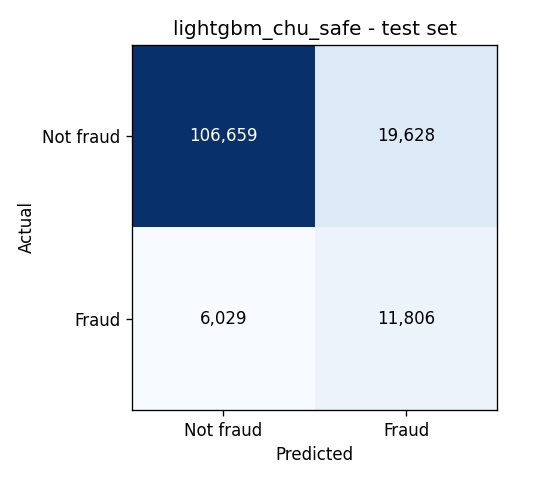

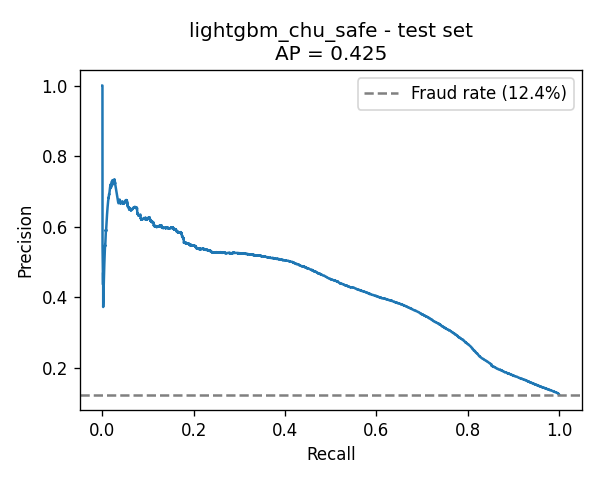

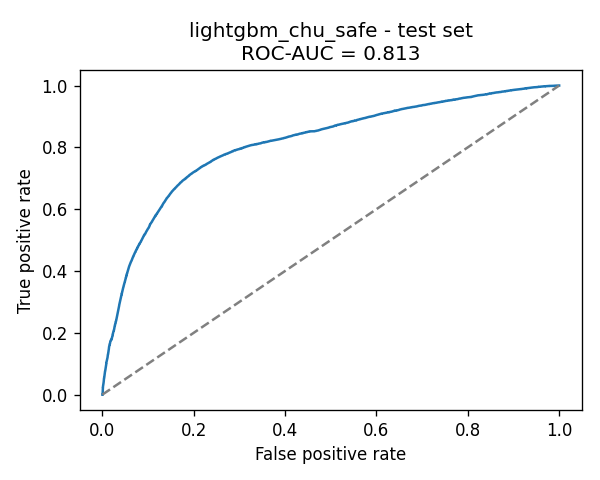

lightgbm_chu_full


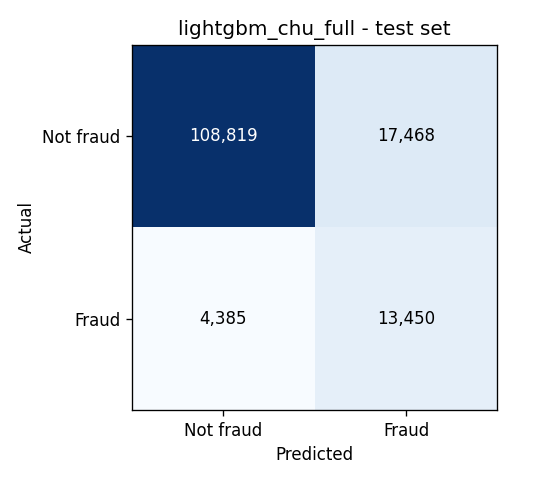

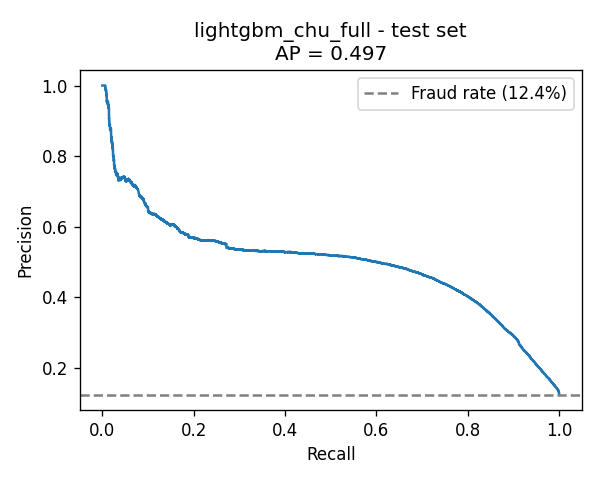

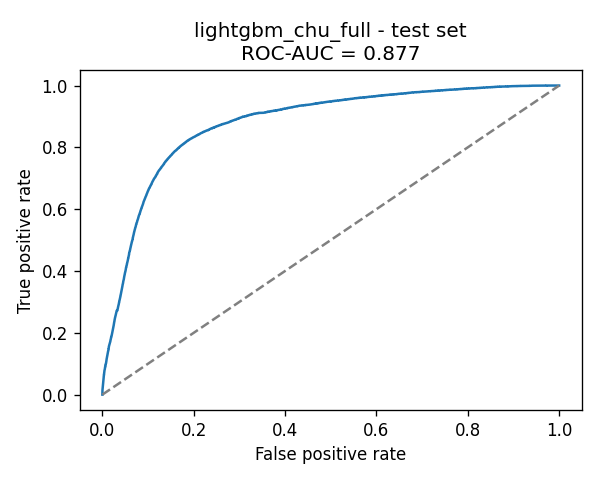

In [12]:
for result in results:
    print(result["run_name"])
    plots = OUTPUT_DIR / result["run_name"] / "plots"
    for filename in ["confusion_matrix_test.png", "precision_recall_test.png", "roc_test.png"]:
        display(Image(filename=str(plots / filename)))

### 13.2 Analyst Workload
A useful fraud model must also fit the team's review capacity. I calculate the alert volume, false-alarm fraction and missed fraud from the **fixed test predictions**. The daily volume below is an average across calendar days in the test period, not a guarantee of equal daily demand.

In [13]:
test_mask = split == "Test"
test_dates = pd.to_datetime(df_safe.loc[test_mask, "order_date"])
test_days = (test_dates.max().normalize() - test_dates.min().normalize()).days + 1
workload_rows = []
for r in results:
    t = r["test"]
    alerts = t["tp"] + t["fp"]
    workload_rows.append({"Dataset": r["dataset_type"], "Flagged orders": alerts,
        "Flagged share": alerts / sum(t[k] for k in ["tp", "tn", "fp", "fn"]),
        "Average flags per calendar day": alerts / test_days,
        "False alarms": t["fp"], "False-alarm share of alerts": 1-t["precision"],
        "Genuine-order false-positive rate": t["fp"] / (t["fp"] + t["tn"]),
        "Missed fraud": t["fn"]})
workload_table = pd.DataFrame(workload_rows).set_index("Dataset")
display(workload_table.round(4))
workload_table.to_csv(REPORT_DIR / "analyst_workload.csv")

,Flagged orders,Flagged share,Average flags per calendar day,False alarms,False-alarm share of alerts,Genuine-order false-positive rate,Missed fraud
Dataset,,,,,,,
safe,31434,0.2181,1122.6429,19628,0.6244,0.1554,6029
full,30918,0.2145,1104.2143,17468,0.5650,0.1383,4385


### Insight for Trust and Safety
Safe flags **31,434 orders**, or **21.81%** of all test orders. Across **28 calendar days**, this averages approximately **1,123 alerts per day**.

**62.44% of alerts are false alarms**, while **15.54% of all genuine orders** are wrongly flagged. These percentages have different denominators: the first describes analyst workload, and the second describes the effect on genuine customers.

The model is useful for prioritizing manual investigation, but it should not be described as ready for unrestricted automatic blocking. Review capacity has not been supplied, so the workload cannot be declared acceptable from these scores alone.

## 14. Validation versus Test Performance
The same Safe model and the same threshold are evaluated in both periods. This checks whether the validation-selected rule holds up on later orders. I do not choose a new cutoff using Test.

In [14]:
period_comparison = pd.DataFrame({
    "Validation": result_safe["validation"], "Test": result_safe["test"]
}).loc[["precision", "recall", "f1", "average_precision", "roc_auc"]]
period_comparison["Test minus Validation"] = period_comparison["Test"] - period_comparison["Validation"]
display(period_comparison.round(4))
period_comparison.to_csv(REPORT_DIR / "validation_test_comparison.csv")

,Validation,Test,Test minus Validation
precision,0.4748,0.3756,-0.0992
recall,0.6829,0.6620,-0.0209
f1,0.5601,0.4792,-0.0809
average_precision,0.5338,0.4247,-0.1090
roc_auc,0.8529,0.8129,-0.0400


### Insight from the Later Test Period
Precision changes from **47.48% to 37.56%**, recall from **68.29% to 66.20%**, and AP from **0.5338 to 0.4247**.

The baseline performs worse on the later period at this fixed rule. This is consistent with temporal distribution change; fraud prevalence also differs between periods and influences precision and AP. These results do not identify one proven cause, and they do not establish model overfitting on their own.

The practical implication is to monitor precision, recall and alert volume on later labeled orders. Retraining on recent data should be evaluated through the team pipeline rather than assuming this validation threshold will remain suitable indefinitely.

### 14.1 Overfitting, Underfitting and Generalisation Check

Validation-to-test degradation alone cannot distinguish overfitting from changes in the data. I therefore score the **already fitted Safe model** on Train as a diagnostic and compare it with the existing held-out results. This does not refit the model or change its parameters or threshold.

Training scores are optimistic because those orders fitted the trees. AP and precision also depend on fraud prevalence, so differences across these periods must be interpreted with the class rates beside them.

In [15]:
train_mask = split == "Train"
X_train_diagnostic = df_safe.loc[train_mask, safe_features].astype("float32")
y_train_diagnostic = df_safe.loc[train_mask, "is_fraud"].to_numpy()
train_prob_diagnostic = model_safe.predict_proba(X_train_diagnostic)[:, 1]
train_diagnostic = mu.evaluate(y_train_diagnostic, train_prob_diagnostic, result_safe["threshold"])
generalisation_rows = []
for name, scores in [("Train", train_diagnostic), ("Validation", result_safe["validation"]), ("Test", result_safe["test"])]:
    generalisation_rows.append({"Split": name,
        "Fraud rate": float(split_summary.loc[name, "fraud_rate"]),
        "Precision": scores["precision"], "Recall": scores["recall"],
        "F1": scores["f1"], "Average precision": scores["average_precision"],
        "ROC-AUC": scores["roc_auc"]})
generalisation_table = pd.DataFrame(generalisation_rows).set_index("Split")
display(generalisation_table.round(4))
generalisation_table.to_csv(REPORT_DIR / "train_validation_test_diagnostic.csv")
del X_train_diagnostic, y_train_diagnostic, train_prob_diagnostic

,Fraud rate,Precision,Recall,F1,Average precision,ROC-AUC
Split,,,,,,
Train,0.1015,0.3216,0.6367,0.4274,0.4484,0.8208
Validation,0.1358,0.4748,0.6829,0.5601,0.5338,0.8529
Test,0.1237,0.3756,0.6620,0.4792,0.4247,0.8129


### Interpretation of Model Fit

The Safe model's training AP is **0.4484**, compared with **0.5338** on Validation and **0.4247** on Test. Its training ROC-AUC is **0.8208**, compared with **0.8529** and **0.8129** respectively. Training F1 at the fixed threshold is **0.4274**.

- **Potential overfitting:** substantially stronger training discrimination than held-out discrimination would suggest that some learned patterns do not transfer. However, these periods differ in prevalence and time, so the gap is not a controlled proof of overfitting. In this run, both training AP and ROC-AUC are lower than Validation, so there is no obvious training-over-validation advantage indicating memorisation; that does not rule out overfitting under other conditions.
- **Potential underfitting:** weak training and held-out discrimination together would suggest insufficient useful signal or model capacity. Poor operational precision alone does not establish underfitting: prevalence, class weighting and the threshold also matter. The observed training ROC-AUC is above the random-ranking reference of 0.5, so the model has learned a signal; the evidence does not justify declaring severe underfitting.
- **Observed generalisation limitation:** validation AP and precision fall on the later test period. Distribution change, feature limitations and model fit are possible contributors. The notebook does not isolate one cause.

The appropriate response is to examine performance on additional chronological periods and monitor recent labeled orders before deciding whether retraining, different regularisation or better inputs would help. Test results remain diagnostic evidence, not a basis for selecting a new threshold.

## 15. Safe versus Full Comparison
The hyperparameters, seed, split boundaries and threshold are held fixed. Both models are evaluated on the same test orders. The additional customer snapshot features are the intended experimental difference.

,lightgbm_chu_safe,lightgbm_chu_full,Full minus Safe
Precision (fraud),0.3756,0.4350,0.0594
Recall (fraud),0.6620,0.7541,0.0922
F1 (fraud),0.4792,0.5518,0.0725
Average precision,0.4247,0.4971,0.0724
ROC-AUC,0.8129,0.8773,0.0644


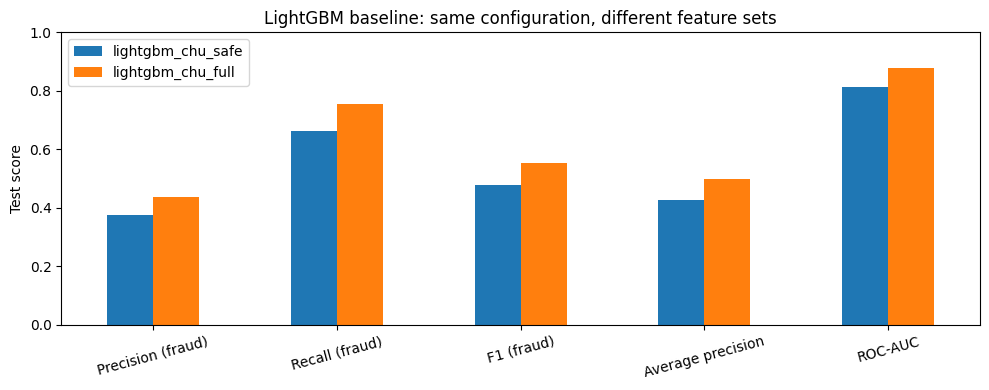

In [16]:
metrics = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC"]
difference = comparison.loc[metrics].astype(float).copy()
difference["Full minus Safe"] = difference.iloc[:, 1] - difference.iloc[:, 0]
display(difference.round(4))
ax = comparison.loc[metrics].astype(float).plot.bar(figsize=(10, 4), rot=15)
ax.set_ylim(0, 1)
ax.set_title("LightGBM baseline: same configuration, different feature sets")
ax.set_ylabel("Test score")
plt.tight_layout()
plt.show()

### Insight from Adding Snapshot Features

| Test metric | Safe | Full |
|---|---:|---:|
| Precision | 37.56% | 43.50% |
| Recall | 66.20% | 75.41% |
| F1 | 0.4792 | 0.5518 |
| Average precision | 0.4247 | 0.4971 |
| ROC-AUC | 0.8129 | 0.8773 |

Full improves AP by **+0.0724**, catches **1,644 more fraud orders**, and produces **-2,160 false alarms** relative to Safe at the shared threshold.

This is a measurable predictive benefit on the historical test set. It is **not sufficient evidence to use Full in production**, because the snapshot values may include activity after the order. The monthly analysis below examines that concern without treating the Full score as a production guarantee.

## 16. Potential Data Leakage Analysis
Customer snapshots are potentially different from information recorded at the time of each order. For example, a recent-activity total could include transactions made after an older order. If that happened, the model would receive information unavailable during the real fraud assessment.

The team's assumed snapshot date is around 11 May 2023, but it has not been confirmed. I compare Safe and Full AP by month **after the training cutoff**. March therefore covers only orders after 15 March; April includes validation and test orders. These are unseen-to-training months, not three independent test sets.

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.94,0.560612,0.566876,0.006264
1,2023-04,148855,12.61,0.443071,0.500085,0.057015
2,2023-05,57450,12.57,0.449495,0.523173,0.073678


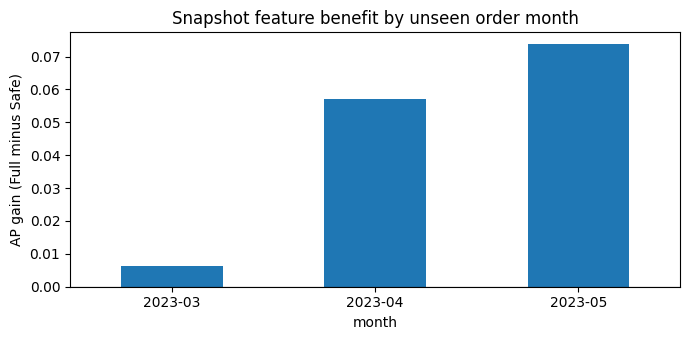

In [17]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)
by_month.to_csv(REPORT_DIR / "monthly_comparison.csv", index=False)
ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False,
                   rot=0, figsize=(7, 3.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("AP gain (Full minus Safe)")
ax.set_title("Snapshot feature benefit by unseen order month")
plt.tight_layout()
plt.show()

### Insight from the Monthly Comparison

| Unseen-to-training month | Safe AP | Full AP | Full minus Safe |
|---|---:|---:|---:|
| 2023-03 | 0.5606 | 0.5669 | +0.0063 |
| 2023-04 | 0.4431 | 0.5001 | +0.0570 |
| 2023-05 | 0.4495 | 0.5232 | +0.0737 |

The Full advantage grows from **+0.0063** in the earliest reported month to **+0.0737** in the latest. This pattern is consistent with snapshot features becoming more informative near the assumed snapshot date. It supports investigating temporal leakage, but does not prove it: changing fraud patterns, customer composition and feature usefulness are also possible explanations.

**Decision:** retain Full for exploratory analysis and keep the uncertain snapshots out of the production candidate. Ask the data owner for snapshot timestamps or dated customer histories, so features can be reconstructed **as of each order**. Removing known-risk inputs does not replace checking the timing of the remaining Safe features.

## 17. Feature Importance
I use **gain importance**: the total reduction in the training objective attributed to splits on a feature, normalized across the ensemble. This differs from split-count importance and from the permutation method used in some teammates' notebooks.

Higher gain means a feature contributes more to this fitted model. It does not show whether its value raises or lowers risk, establish causality, or prove leakage. Correlated predictors can share or substitute for one another's importance. Red bars identify snapshot features.

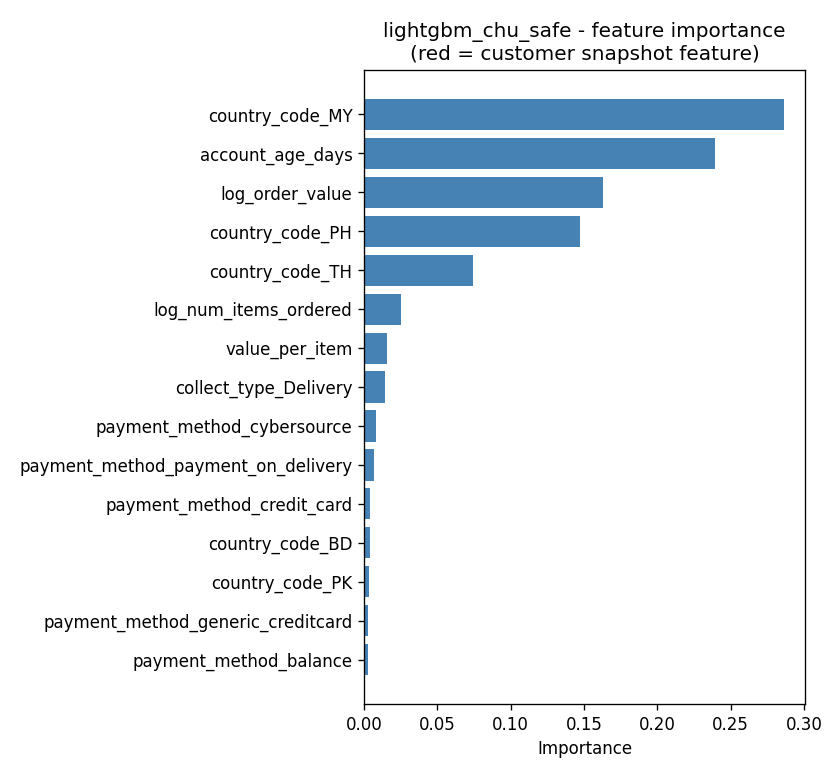

,feature,importance
0,country_code_MY,0.286338
1,account_age_days,0.239025
2,log_order_value,0.162591
3,country_code_PH,0.147043
4,country_code_TH,0.074002
5,log_num_items_ordered,0.025422
6,value_per_item,0.015614
7,collect_type_Delivery,0.014318
8,payment_method_cybersource,0.008142
9,payment_method_payment_on_delivery,0.006622


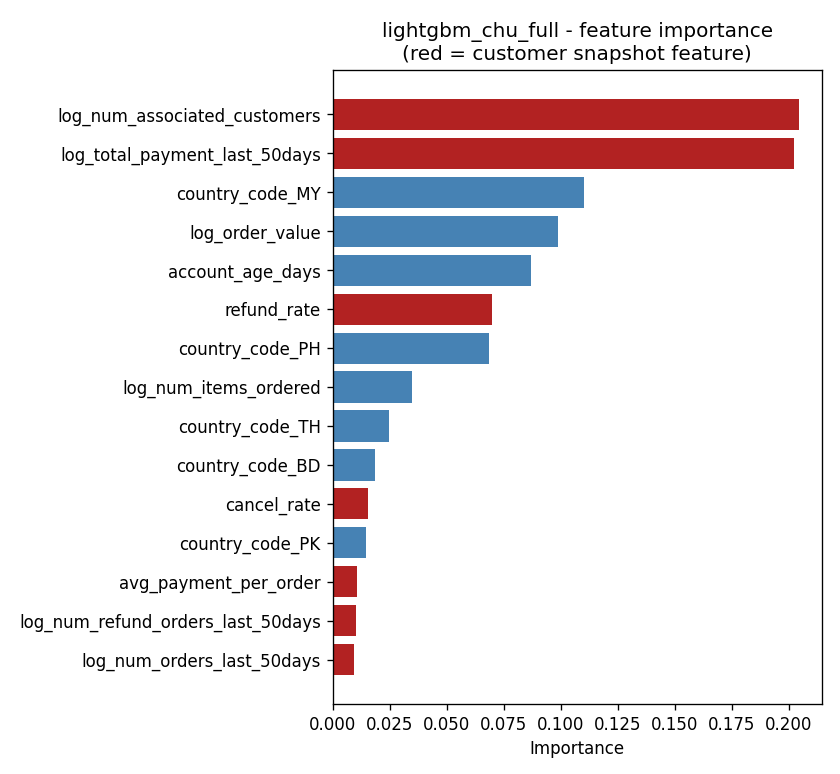

,feature,importance
0,log_num_associated_customers,0.204427
1,log_total_payment_last_50days,0.202428
2,country_code_MY,0.110141
3,log_order_value,0.099059
4,account_age_days,0.086866
5,refund_rate,0.069927
6,country_code_PH,0.068484
7,log_num_items_ordered,0.034943
8,country_code_TH,0.024930
9,country_code_BD,0.018566


Full gain importance from snapshot features: 52.5%


In [18]:
for result in results:
    display(Image(filename=str(OUTPUT_DIR / result["run_name"] / "plots" / "feature_importance.png")))
    display(result["importance"].head(15))
snapshot_share = result_full["importance"].loc[
    result_full["importance"]["feature"].isin(SNAPSHOT_FEATURES), "importance"
].sum()
print(f"Full gain importance from snapshot features: {snapshot_share:.1%}")

### Insight from the Important Features
The top Safe features are:

1. `country_code_MY` - 28.6% of normalized gain.
2. `account_age_days` - 23.9% of normalized gain.
3. `log_order_value` - 16.3% of normalized gain.
4. `country_code_PH` - 14.7% of normalized gain.
5. `country_code_TH` - 7.4% of normalized gain.

The model relies strongly on country indicators, account age and order value in this run. A country's importance does not mean all customers from that country are fraudulent, and gain importance does not provide the direction of its effect.

Snapshot features contribute **52.5% of Full gain importance**, showing reliance on inputs whose historical availability is uncertain. This adds a reason to investigate provenance; it is not an independent leakage test. Any production use should include checks on genuine-customer false-positive rates across relevant groups.

## 18. MLflow Tracking and Reload Verification

| Recorded item | Evidence |
|---|---|
| Experiment | `SP-buy-Fraud-Detection` |
| Final run names | `chu_lightgbm_safe_v1`, `chu_lightgbm_full_v1` |
| Parameters | Baseline settings, seed, threshold, row counts, feature count, dataset SHA-256 |
| Metrics | Validation/test precision, recall, F1, AP, ROC-AUC, confusion counts and runtime |
| Artifacts | Model, feature list, confusion matrix, PR/ROC curves, importance plot and CSV |
| Eligibility tags | Safe is eligible for selection; Full is exploratory |

Reload checks compare probabilities on validation inputs, not just successful file creation. For serving, use the saved threshold with `predict_proba`; the estimator's plain `predict()` does not implement this custom cutoff.

These runs use **local** storage. They are not yet evidence of shared AWS logging, a registry entry or champion promotion. Those decisions belong to the team integration and model comparison process.

In [19]:
from mlflow.tracking import MlflowClient
client = MlflowClient() if LOG_TO_MLFLOW else None
for result, model, frame in [(result_safe, model_safe, df_safe), (result_full, model_full, df_full)]:
    if LOG_TO_MLFLOW:
        run_record = client.get_run(result["mlflow_run_id"])
        restored = mlflow.sklearn.load_model(run_record.data.tags["logged_model_uri"])
        sample = frame.loc[split == "Validation", result["features"]].head(100).astype("float32")
        np.testing.assert_allclose(model.predict_proba(sample), restored.predict_proba(sample),
                                   rtol=1e-7, atol=1e-9)
        assert run_record.data.tags["production_eligible"] == str(result["production_eligible"]).lower()
        assert run_record.data.tags["tracking_location"] == "local"
        print(mu.mlflow_run_name(result), "reload passed | run:", result["mlflow_run_id"])
        del restored
    payload = {k: v for k, v in result.items() if k != "importance"}
    (OUTPUT_DIR / result["run_name"] / "result.json").write_text(
        json.dumps(payload, indent=2, default=str), encoding="utf-8")
print("MLflow:", local_uri)
print("Reports:", REPORT_DIR)

chu_lightgbm_safe_v1 reload passed | run: 2a68ee31622646358aec2b5020cf205e


chu_lightgbm_full_v1 reload passed | run: f33f6bdb156a4ffab5d2c26b18983642
MLflow: sqlite:///C:/Users/User/Desktop/AMLOPs/CA1/MLOps_CA1_group5/mlruns/mlflow.db
Reports: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5\outputs\lightgbm_chu


## 19. Conclusion and Limitations
The conclusion separates predictive results from deployment eligibility. A higher historical Full score does not override uncertain feature timing. This notebook supports a baseline decision; it does not claim that the settings or threshold are optimal.

### Final Baseline Conclusion
**LightGBM Safe is the candidate from this notebook for team comparison.** It achieves **37.56% precision**, **66.20% recall**, **0.4792 F1** and **0.4247 average precision** on later test orders.

The model catches **11,806 fraud orders**, but misses **6,029** and raises **19,628 false alarms**. Therefore, it provides useful fraud prioritization while leaving a substantial review burden. The stakeholder's preference for high precision is not automatically satisfied by maximum-F1 threshold selection.

**Full scores higher but remains exploratory.** Its stronger historical performance, growing monthly advantage and reliance on snapshots are reasons to examine temporal leakage. They are not proof of leakage, and historical availability remains unresolved.

### Limitations

- **One baseline and one temporal holdout:** no claim of optimal settings or reliable performance in every future period.
- **Later-period degradation:** validation performance does not carry over unchanged to Test; the mechanism needs further investigation.
- **Probability interpretation:** class weighting changes the score distribution; scores are not calibrated risk estimates.
- **Threshold objective:** maximum validation F1 may not match desired precision or daily review capacity.
- **Feature timing:** the snapshot date is unverified, and Safe customer-derived inputs still require provenance checks.
- **Importance interpretation:** gain does not give direction, causality or a guarantee of fairness.
- **Runtime scope:** fitting took **1.18 seconds for Safe** and **1.75 seconds for Full** in this run. The Safe split/train/evaluate/save/log sequence took **8.46 seconds**. These exclude upstream ETL and do not establish the complete group pipeline's three-minute limit.

### Next Steps for the Team
Compare eligible Safe models under clearly stated threshold rules and compatible data versions. Agree on the precision/recall and workload trade-off, log final runs to shared MLflow, and let the team choose registry contenders and the champion. Test retraining with old and new data as part of the full ETL demo. Full should remain excluded until its features can be verified at order time.

In [20]:
# Save the values used by the written discussion for this execution.
s = result_safe["test"]
f = result_full["test"]
v = result_safe["validation"]
default_scores = threshold_table.loc["Default 0.5"]
chosen_scores = threshold_table.loc["Chosen validation F1"]
context = {
    "rows": f"{len(df_safe):,}", "overall_rate": f"{df_safe.is_fraud.mean():.2%}",
    "safe_features": str(len(safe_features)), "full_features": str(len(full_features)),
    "snapshot_count": str(len(extra_features)), "test_days": str(test_days),
    "test_fraud": f"{s['tp']+s['fn']:,}", "test_genuine": f"{s['tn']+s['fp']:,}",
    "majority_accuracy": f"{1-df_safe.loc[test_mask, 'is_fraud'].mean():.2%}",
    "threshold": f"{result_safe['threshold']:.4f}",
    "default_precision": f"{default_scores['Precision']:.2%}",
    "default_recall": f"{default_scores['Recall']:.2%}", "default_f1": f"{default_scores['F1']:.4f}",
    "default_flagged": f"{int(default_scores['Flagged']):,}", "default_fp": f"{int(default_scores['False alarms']):,}",
    "threshold_flag_change": f"{int(chosen_scores['Flagged']-default_scores['Flagged']):+,}",
    "threshold_tp_change": f"{int(chosen_scores['Caught fraud']-default_scores['Caught fraud']):+,}",
    "val_flagged": f"{v['tp']+v['fp']:,}", "val_fp": f"{v['fp']:,}",
    "fraud_per_ten": f"{10*s['precision']:.1f}",
    "precision_lift": f"{s['precision']/df_safe.loc[test_mask, 'is_fraud'].mean():.2f}",
    "safe_flagged": f"{s['tp']+s['fp']:,}",
    "flagged_share": f"{(s['tp']+s['fp'])/split_summary.loc['Test','orders']:.2%}",
    "flags_per_day": f"{(s['tp']+s['fp'])/test_days:,.0f}",
    "false_alert_share": f"{1-s['precision']:.2%}", "genuine_fpr": f"{s['fp']/(s['fp']+s['tn']):.2%}",
    "ap_gain": f"{f['average_precision']-s['average_precision']:+.4f}",
    "extra_caught": f"{f['tp']-s['tp']:,}", "fp_change": f"{f['fp']-s['fp']:+,}",
    "month_rows": "\n".join(f"| {r.month} | {r.safe_AP:.4f} | {r.full_AP:.4f} | {r.gain_full_minus_safe:+.4f} |" for r in by_month.itertuples()),
    "first_month_gain": f"{by_month.iloc[0]['gain_full_minus_safe']:+.4f}",
    "last_month_gain": f"{by_month.iloc[-1]['gain_full_minus_safe']:+.4f}",
    "importance_rows": "\n".join(f"{i+1}. `{r.feature}` - {r.importance:.1%} of normalized gain." for i,r in enumerate(result_safe['importance'].head(5).itertuples())),
    "snapshot_share": f"{snapshot_share:.1%}", "safe_fit": f"{result_safe['train_seconds']:.2f}",
    "full_fit": f"{result_full['train_seconds']:.2f}", "safe_pipeline": f"{safe_pipeline_seconds:.2f}",
}
for name, key in [("train", "Train"), ("val", "Validation"), ("test", "Test")]:
    context[f"{name}_rows"] = f"{int(split_summary.loc[key,'orders']):,}"
    context[f"{name}_rate"] = f"{split_summary.loc[key,'fraud_rate']:.2%}"
for prefix, scores in [("safe", s), ("full", f), ("val", v)]:
    for key in ["precision", "recall", "accuracy"]:
        context[f"{prefix}_{key}"] = f"{scores[key]:.2%}"
    for key, alias in [("f1", "f1"), ("average_precision", "ap"), ("roc_auc", "roc")]:
        context[f"{prefix}_{alias}"] = f"{scores[key]:.4f}"
    for key in ["tp", "tn", "fp", "fn"]:
        context[f"{prefix}_{key}"] = f"{scores[key]:,}"
context.update({
    "train_ap": f"{train_diagnostic['average_precision']:.4f}",
    "train_roc": f"{train_diagnostic['roc_auc']:.4f}",
    "train_f1": f"{train_diagnostic['f1']:.4f}",
})
(REPORT_DIR / "report_context.json").write_text(json.dumps(context, indent=2), encoding="utf-8")
print(f"Notebook workflow elapsed: {time.perf_counter()-workflow_started:.1f}s")
print("Command: python src/lightgbm_chu.py --no-mlflow")
print("Interpretations describe this saved execution; review them after changing data or settings.")

Notebook workflow elapsed: 37.2s
Command: python src/lightgbm_chu.py --no-mlflow
Interpretations describe this saved execution; review them after changing data or settings.


### 19.1 Proposed Improvements and Their Expected Effects

These are **proposals, not additional implemented model versions**. The baseline remains fixed. The task clarification makes implementation optional; what matters here is explaining a justified next step and its trade-off.

| Observed limitation | Proposed change | Expected precision and recall effect | How to assess it fairly |
|---|---|---|---|
| Many genuine orders are flagged; the maximum-F1 objective does not explicitly prioritize precision | Agree a minimum precision or review-capacity objective with the Product Owner, then evaluate stricter cutoffs on Validation | A stricter cutoff may improve precision and reduce alerts, while reducing recall. Precision is not guaranteed to increase monotonically at every cutoff | Compare the validation PR curve, caught fraud, false alarms and alerts per day. Fix the policy before evaluating a future holdout |
| Precision and AP decline on the later Test period | Retrain on recent correctly labeled orders; evaluate several chronological windows | More recent patterns may improve later precision and recall, but noisy recent labels or short windows can also harm performance | Use repeatable time-based backtests and assess later periods under the same reporting rule |
| Some learned patterns may not generalise | If the fit diagnostic supports excessive complexity, compare fewer leaves, larger minimum leaf sizes or stronger regularisation | Reduced overfitting may improve held-out precision; excessive regularisation can lose fraud patterns and reduce recall | Change one factor at a time using Train and Validation. Do not infer the best setting from the current Test scores |
| Some useful customer history has uncertain historical availability | Obtain dated histories and construct customer features as of each order | Valid history could improve both ranking and precision/recall; the current Full benefit may shrink when future information is removed | Verify timestamps, exclude post-assessment information, and compare corrected features on a future chronological holdout |
| Weighted scores are not calibrated probabilities | If stakeholders need interpretable risk estimates, evaluate calibration on a reserved development period | Calibration may improve probability interpretation; it does not automatically improve ranking, precision or recall | Assess calibration separately and validate any threshold policy before final evaluation |

**Evidence for the threshold proposal already exists:** on Validation, the chosen cutoff increases precision from **41.41% to 47.48%** relative to 0.5, while recall decreases from **77.86% to 68.29%**. This demonstrates the business trade-off without claiming that an untested stricter policy is better.

**Priority:** first agree the operational precision/recall and workload objective, then investigate later-period stability and feature timing. More complex training is not automatically the most useful next step. No proposed improvement is claimed to have been implemented or validated here.

## 20. Final Decision on the Safe and Full Datasets

**I will use the Safe dataset for the LightGBM production candidate and keep the Full dataset for exploratory comparison only.** Both models used the same baseline settings, chronological split and Safe validation threshold, so this notebook compares feature sets rather than two tuned configurations.

| Test result | Safe dataset | Full dataset |
|---|---:|---:|
| Fraud precision | 37.56% | 43.50% |
| Fraud recall | 66.20% | 75.41% |
| F1-score | 0.4792 | 0.5518 |
| Average precision | 0.4247 | 0.4971 |
| Decision | Retain for team model selection | Retain for leakage investigation only |

### Why I Am Not Choosing Full Despite Its Higher Scores
Full improves test average precision by **0.0724** and catches **1,644 more fraud orders** at the shared threshold. However, its additional customer snapshot features may contain activity recorded after an order was assessed. Their availability at prediction time has not been verified.

The Full advantage grows from **+0.0063 AP in March** to **+0.0737 AP in May**, and the snapshot features account for **52.5% of Full gain importance**. These findings are consistent with possible temporal leakage, but **they do not prove that leakage occurred**. Useful customer history and changes in fraud patterns could also contribute. The correct conclusion is that Full's higher scores are not sufficient to justify production use while feature timing remains uncertain.

### What I Will Do with Each Dataset

1. **Safe:** use it for the candidate passed to the team's model comparison and future retraining workflow. Continue checking that each retained input, including customer-derived account age, can be calculated using information available when an order is assessed. Safe is eligible for selection; it is not automatically the team's champion or ready for deployment.
2. **Full:** preserve it for reproducible analysis, feature investigation and comparison. Keep its runs tagged exploratory and do not register or promote the Full model as a production contender while snapshot timing is unresolved. Excluding features from a production model does not require deleting the underlying customer data.
3. **Snapshot features:** request the actual snapshot timestamps or dated customer histories from the data owner. If these inputs can be rebuilt as of each order's assessment time, evaluate that corrected feature set as a separate future experiment. Keep the current Full results as historical exploratory evidence.

### Business Conclusion
The Safe baseline catches about **two-thirds of fraud**, but only about **38 of every 100 alerts are actually fraud**. It produces **19,628 false alarms** and misses **6,029 fraud orders** in the test period. This makes it useful for prioritizing investigation, but its review workload still needs agreement with Trust & Safety. A higher historical score from uncertain features should not take priority over valid inputs and a workable review policy.

**Final recommendation: proceed with Safe for team comparison, keep Full for analysis, and do not claim confirmed leakage or production readiness from this notebook alone.**

## 21. Evidence for Tasks #31 to #34

This notebook documents my **LightGBM contribution**. My separate Extra Trees work provides the second selected algorithm. The table distinguishes the evidence in this notebook from the combined individual and team requirements.

| Task | Evidence provided here | Scope and remaining dependency |
|---|---|---|
| **#31 Select and develop fraud models** | Algorithm justification, preprocessing requirements, fixed parameters and executed Safe/Full training in Sections 2-11 | The requirement for two different algorithms is addressed by **Extra Trees plus LightGBM together**, not by LightGBM Safe/Full alone. Include both notebooks and training scripts in the submission |
| **#32 Train multiple meaningful versions** | Two saved LightGBM fits with 31 versus 41 features, identical baseline parameters and evaluation rules; different feature sets are explicitly documented | Full is an exploratory feature variant, not a valid production alternative while timing is unresolved. My two different trained algorithms also provide meaningful differences in training approach. The team must verify its agreed version count and at least eight documented trained versions across four members |
| **#33 Evaluate performance** | Precision, recall, F1, confusion matrices, AP, ROC-AUC, fixed chronological evaluation, threshold trade-offs, workload and written interpretation in Sections 12-15 | Evaluation is complete for these LightGBM runs. Consistency and results for other members' models require their own evidence; high precision has been evaluated, not assumed to be achieved |
| **#34 Analyse limitations and propose improvements** | Train/validation/test fit diagnostic, generalisation caveats, leakage investigation, limitations and proposals explicitly connected to precision and recall in Sections 14, 16 and 19 | No improved LightGBM configuration is implemented or claimed. Implementation is optional under the task clarification; any future implementation must be compared fairly with the baseline |

**Completion statement:** the notebook supplies evidence for the LightGBM part of all four tasks. The two-algorithm requirement is completed through the companion Extra Trees work, and group-wide completion must be confirmed using every member's deliverables. This document does not certify completion for absent teammates or claim that exploratory Full features are safe for deployment.